# A/B Testing Assignment - Complete Analysis

Compare mean session duration between UI_A and UI_B. The target metric is `session_duration_seconds`, measured in **seconds**. Session duration measures engagement, but alone does not establish overall user experience.

## Hypotheses

- H0: μB − μA = 0
- H1: μB − μA ≠ 0
- Two-sided significance level: 0.05.

This notebook performs exploration, normality assessment, and an independently verified two-sample mean comparison. Step 5 adds the required normal-model probabilities, supplementary empirical rates, and business impact. The completed DOCX and PDF reports are in report/.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
CSV_PATH = ROOT / 'ui_ab_testing_data.csv'
if not CSV_PATH.is_file():
    raise FileNotFoundError('Execute this notebook from the project folder containing ui_ab_testing_data.csv.')
assert Path(sys.executable).resolve() == (ROOT / '.venv' / 'Scripts' / 'python.exe').resolve(), 'Select the project .venv kernel.'
pd.options.display.float_format = '{:.4f}'.format
print('Python:', sys.version.split()[0])
print('Kernel:', sys.executable)
data = pd.read_csv(CSV_PATH)

Python: 3.13.1
Kernel: D:\CSE_21201016_BRAC\DATA_SCIENCE\ASSIGN1_sarwar\.venv\Scripts\python.exe


## First 10 rows and dataset structure

The source CSV is read without modifying it. Timestamp values remain as loaded strings; no transformations are needed for duration exploration.

In [2]:
display(data.head(10))
print('Dimensions (rows, columns):', data.shape)
print('Columns:', data.columns.tolist())
display(data.dtypes.rename('dtype').to_frame())

,user_id,ui_version,timestamp,session_duration_seconds,pages_visited,clicks,errors_encountered,conversion,bounce
0,1,UI_A,15-01-24 2:46,50.4300,2,5,1,0,0
1,2,UI_B,20-01-24 23:28,8.7100,9,6,0,0,0
2,3,UI_A,04-01-24 19:54,88.4000,4,4,0,0,0
3,4,UI_A,20-01-24 22:06,91.6000,3,4,0,1,0
4,5,UI_A,27-01-24 5:12,240.7900,3,3,1,0,0
5,6,UI_B,20-01-24 20:59,138.4400,3,3,0,0,1
6,7,UI_A,11-01-24 6:35,54.0300,4,8,1,0,0
7,8,UI_A,10-01-24 1:37,17.2800,3,7,0,0,0
8,9,UI_A,03-01-24 20:41,76.7800,3,8,0,0,1
9,10,UI_B,29-01-24 22:09,141.4300,4,4,1,0,0


Dimensions (rows, columns): (10000, 9)
Columns: ['user_id', 'ui_version', 'timestamp', 'session_duration_seconds', 'pages_visited', 'clicks', 'errors_encountered', 'conversion', 'bounce']


,dtype
user_id,int64
ui_version,str
timestamp,str
session_duration_seconds,float64
pages_visited,int64
clicks,int64
errors_encountered,int64
conversion,int64
bounce,int64


## Data quality

Count missing values, duplicate rows and session IDs, unexpected UI labels, and invalid durations. Stop for review if problems occur; do not silently drop or alter observations. Unique session IDs alone cannot prove independence.

In [3]:
display(data.isna().sum().rename('missing_values').to_frame())
duration = pd.to_numeric(data['session_duration_seconds'], errors='coerce')
checks = pd.Series({
    'missing_cells': int(data.isna().sum().sum()),
    'duplicate_rows': int(data.duplicated().sum()),
    'duplicate_user_ids': int(data['user_id'].duplicated().sum()),
    'unexpected_ui_labels': int((~data['ui_version'].isin(['UI_A', 'UI_B'])).sum()),
    'non_numeric_or_nonfinite_durations': int((~np.isfinite(duration)).sum()),
    'nonpositive_durations': int((duration <= 0).sum()),
}, name='count')
display(checks.to_frame())
display(data['ui_version'].value_counts(dropna=False).rename('count').to_frame())
assert not checks.any(), 'Data quality issues require review; no rows have been changed.'

,missing_values
user_id,0
ui_version,0
timestamp,0
session_duration_seconds,0
pages_visited,0
clicks,0
errors_encountered,0
conversion,0
bounce,0


,count
missing_cells,0
duplicate_rows,0
duplicate_user_ids,0
unexpected_ui_labels,0
non_numeric_or_nonfinite_durations,0
nonpositive_durations,0


,count
ui_version,
UI_A,5013
UI_B,4987


## Separate groups and calculate descriptive statistics

All observations are retained. Sample standard deviation uses **ddof=1**. Quartiles use linear interpolation; `50%` is the median. Full precision is retained internally and in the CSV; only displayed values are rounded.

In [4]:
ui_a = data.loc[data['ui_version'].eq('UI_A'), 'session_duration_seconds']
ui_b = data.loc[data['ui_version'].eq('UI_B'), 'session_duration_seconds']
# Independent implementation from the command-line script.
statistics = pd.DataFrame({label: values.describe(percentiles=[0.25, 0.5, 0.75])
                           for label, values in [('UI_A', ui_a), ('UI_B', ui_b)]}).T
# Make the sample-SD convention explicit.
statistics['std'] = [ui_a.std(ddof=1), ui_b.std(ddof=1)]
statistics['count'] = statistics['count'].astype('int64')
statistics.index.name = 'ui_version'
display(statistics)

,count,mean,std,min,25%,50%,75%,max
ui_version,,,,,,,,
UI_A,5013,99.6631,71.5636,1.6100,47.6700,81.8100,133.5300,525.9500
UI_B,4987,126.2585,83.6444,2.2500,65.7350,109.1500,167.3500,666.5100


## Verify Step 1 references and script agreement, then save

Reference values below are used only for assertions. Every reported statistic is calculated from the CSV. Run the script first so its saved output can be compared before the notebook writes the output file.

In [5]:
for label, n, mean, sd in [('UI_A', 5013, 99.6631, 71.5636), ('UI_B', 4987, 126.2585, 83.6444)]:
    assert statistics.loc[label, 'count'] == n
    np.testing.assert_allclose(statistics.loc[label, ['mean', 'std']], [mean, sd], rtol=0, atol=0.00005)
output = ROOT / 'results' / 'descriptive_statistics.csv'
script_statistics = pd.read_csv(output, index_col='ui_version', float_precision='round_trip')
pd.testing.assert_frame_equal(statistics, script_statistics, check_exact=False, rtol=1e-12, atol=1e-12)
statistics.to_csv(output)
print('PASS: Step 1 references verified; all script and notebook statistics agree within 1e-12 tolerance.')
print('Saved full-precision statistics:', output.relative_to(ROOT))

PASS: Step 1 references verified; all script and notebook statistics agree within 1e-12 tolerance.
Saved full-precision statistics: results\descriptive_statistics.csv


## Standard deviation versus standard error

**Standard deviation (SD)** describes variation among individual session durations. **Standard error (SE)** describes uncertainty in an estimated mean; for independent observations it is SD / √n. A larger sample can reduce SE without reducing individual-session variation. The table reports sample SD, not SE; SE is not calculated in this step.

## Assignment preview discrepancy

The assignment preview gives SDs of 68.45 seconds for UI_A and 71.23 seconds for UI_B. The comparison below uses calculated CSV sample SDs. The difference exceeds rounding; the original files do not establish its cause. Use the CSV as authoritative.

In [6]:
preview = pd.Series({'UI_A': 68.45, 'UI_B': 71.23}, name='preview_sd')
comparison = pd.concat([preview, statistics['std'].rename('csv_sample_sd')], axis=1)
comparison['csv_minus_preview'] = comparison['csv_sample_sd'] - comparison['preview_sd']
display(comparison)

,preview_sd,csv_sample_sd,csv_minus_preview
UI_A,68.4500,71.5636,3.1136
UI_B,71.2300,83.6444,12.4144


## Step 2 scope checkpoint (completed previously)

The preceding exploration retains all original observations. The normality assessment authorized in Step 3 follows below.

## Step 3: assess normality

For each group, Shapiro-Wilk tests **H0: individual session durations follow a normal distribution**, against **H1: they do not follow a normal distribution**. Use alpha = 0.05. A small p-value provides evidence against normality; a large p-value means insufficient evidence to reject and does not prove normality. All observations are used, without transforming durations or deleting extremes.

In [7]:
import warnings
from scipy import stats as scipy_stats

normality_rows = []
for label, values in [('UI_A', ui_a), ('UI_B', ui_b)]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        w_statistic, p_value = scipy_stats.shapiro(values)
    messages = [f'{warning.category.__name__}: {warning.message}' for warning in caught]
    for message in messages:
        print(f'{label} Shapiro-Wilk warning: {message}')
    normality_rows.append({
        'ui_version': label, 'count': len(values),
        'sample_skewness': scipy_stats.skew(values, bias=False),
        'shapiro_W': w_statistic, 'shapiro_p_value': p_value,
        'warning': ' | '.join(messages)
    })
normality = pd.DataFrame(normality_rows).set_index('ui_version')
normality_display = normality.drop(columns='warning').copy()
for column in ['sample_skewness', 'shapiro_W']:
    normality_display[column] = normality_display[column].map('{:.6f}'.format)
normality_display['shapiro_p_value'] = normality_display['shapiro_p_value'].map('{:.6e}'.format)
display(normality_display)  # Formatting affects only this display copy.
print('Decision at alpha=0.05:')
for label, row in normality.iterrows():
    print(label, 'Reject normality H0' if row['shapiro_p_value'] < 0.05 else 'Fail to reject normality H0')

UI_A Shapiro-Wilk warning: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5013.


,count,sample_skewness,shapiro_W,shapiro_p_value
ui_version,,,,
UI_A,5013,1.367327,0.895352,5.031549e-50
UI_B,4987,1.368853,0.906892,5.703987e-48


Decision at alpha=0.05:
UI_A Reject normality H0
UI_B Reject normality H0


### Verify and save numerical results

Recompute normality statistics independently of the script and compare every numerical result, plus the captured warning. The script must have run first. P-values remain full precision in the CSV and scientific notation in displays.

In [8]:
normality_path = ROOT / 'results' / 'normality_assessment.csv'
script_normality = pd.read_csv(normality_path, index_col='ui_version', float_precision='round_trip', keep_default_na=False)
pd.testing.assert_frame_equal(normality, script_normality, check_exact=False, rtol=1e-12, atol=0)
normality.to_csv(normality_path)
print('PASS: script and notebook normality results and warnings agree.')
# Recheck the preceding descriptive statistics after normality assessment.
saved_descriptive = pd.read_csv(ROOT / 'results' / 'descriptive_statistics.csv', index_col='ui_version', float_precision='round_trip')
pd.testing.assert_frame_equal(statistics, saved_descriptive, check_exact=False, rtol=1e-12, atol=1e-12)
print('PASS: descriptive statistics unchanged.')

PASS: script and notebook normality results and warnings agree.
PASS: descriptive statistics unchanged.


### Histograms and normal Q-Q plots

Separate histograms use exactly 25 bins with shared boundaries spanning the pooled minimum to maximum, identical x limits, and identical frequency-axis limits. Each normal Q-Q plot uses `scipy.stats.probplot(..., dist="norm", fit=True)` and shows its least-squares fitted reference line. Every observation is retained. The same plotting function is used by both entry points to keep exported figures consistent.

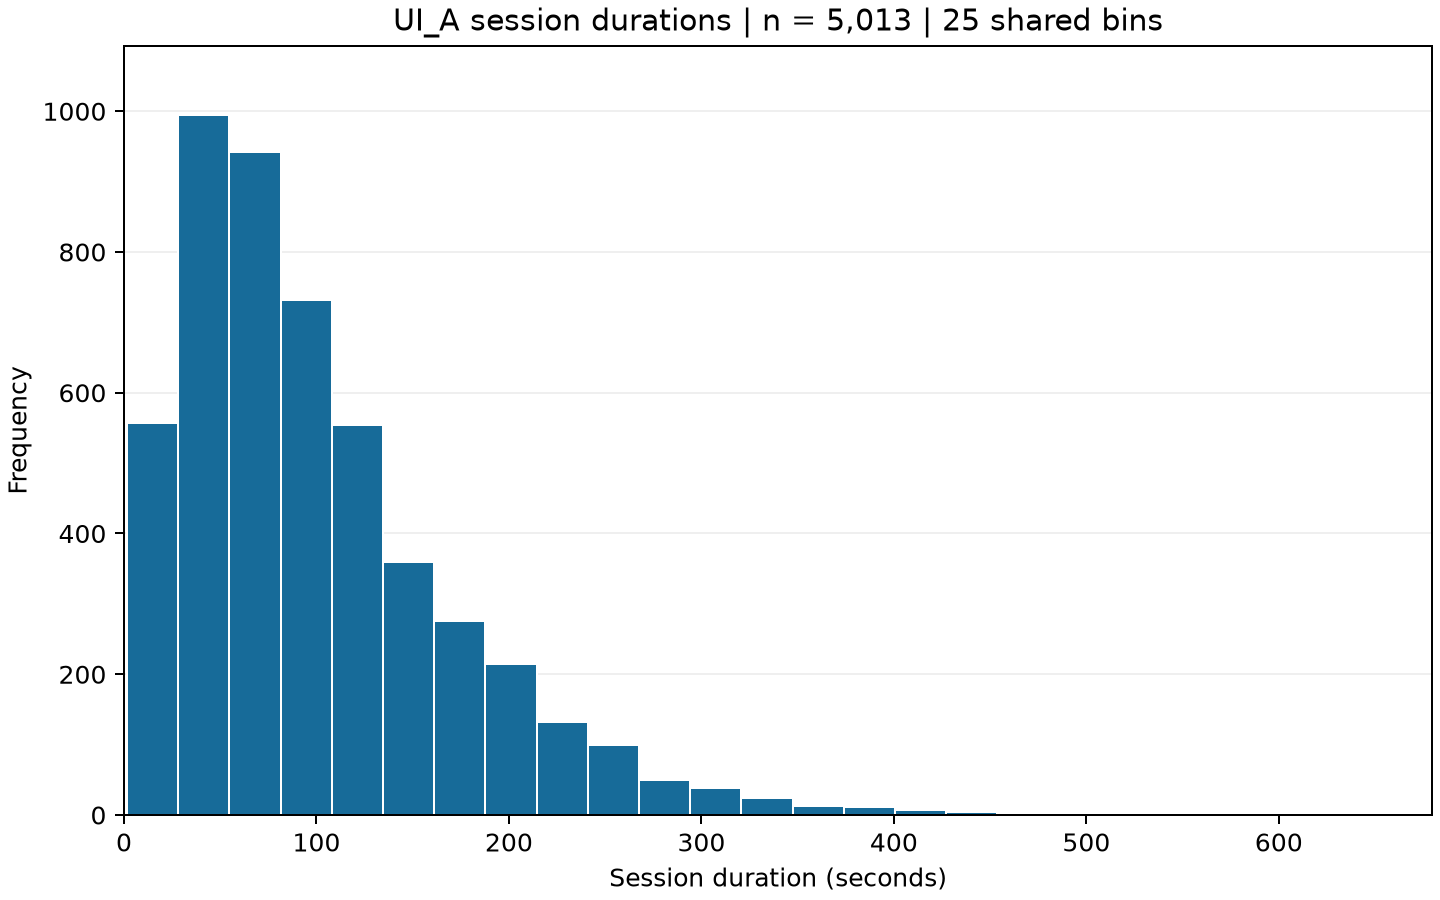

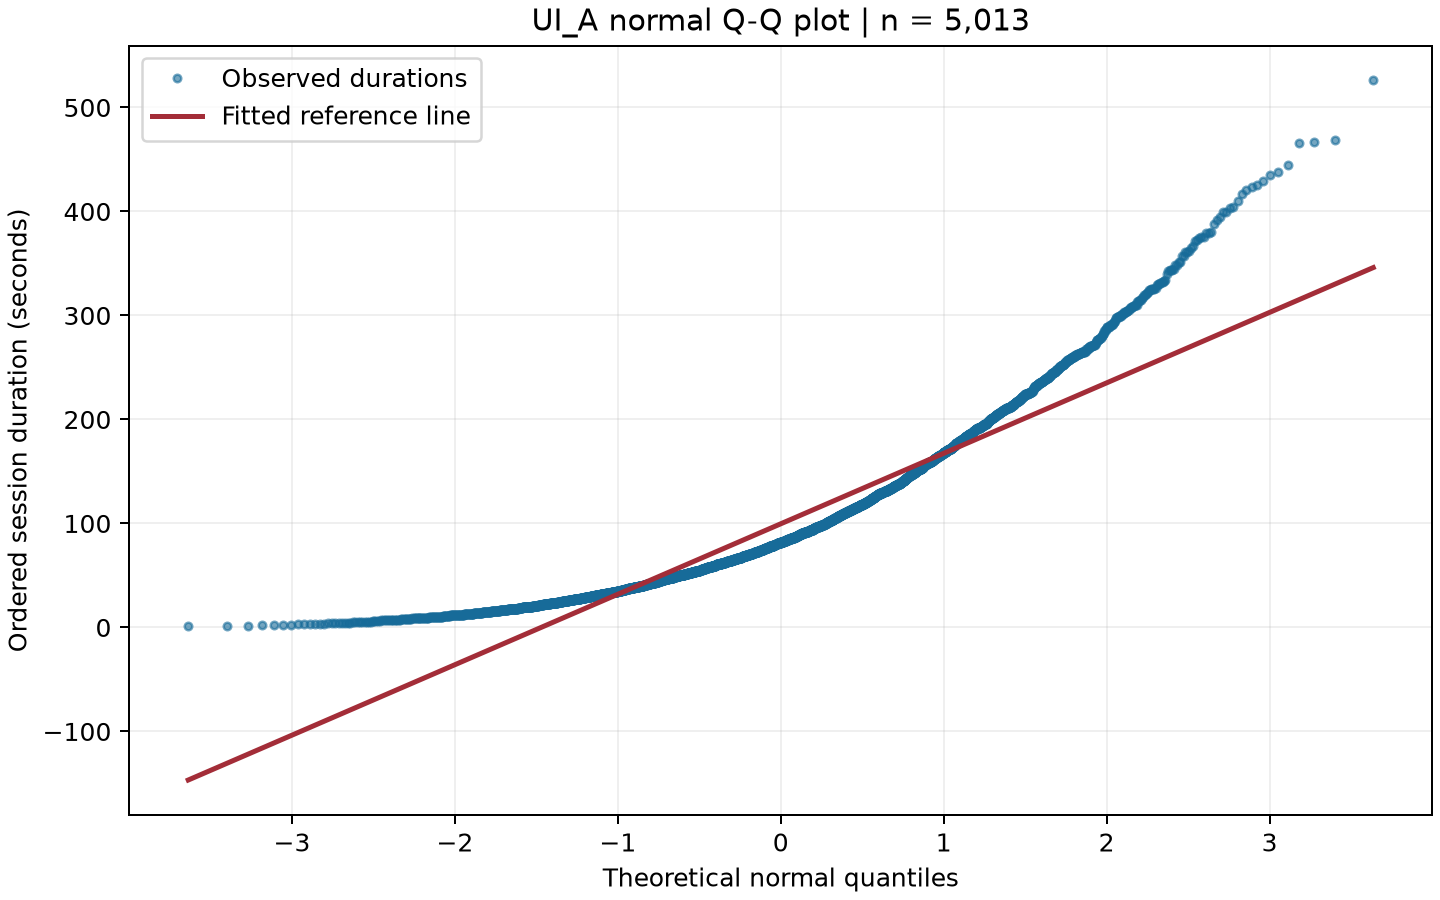

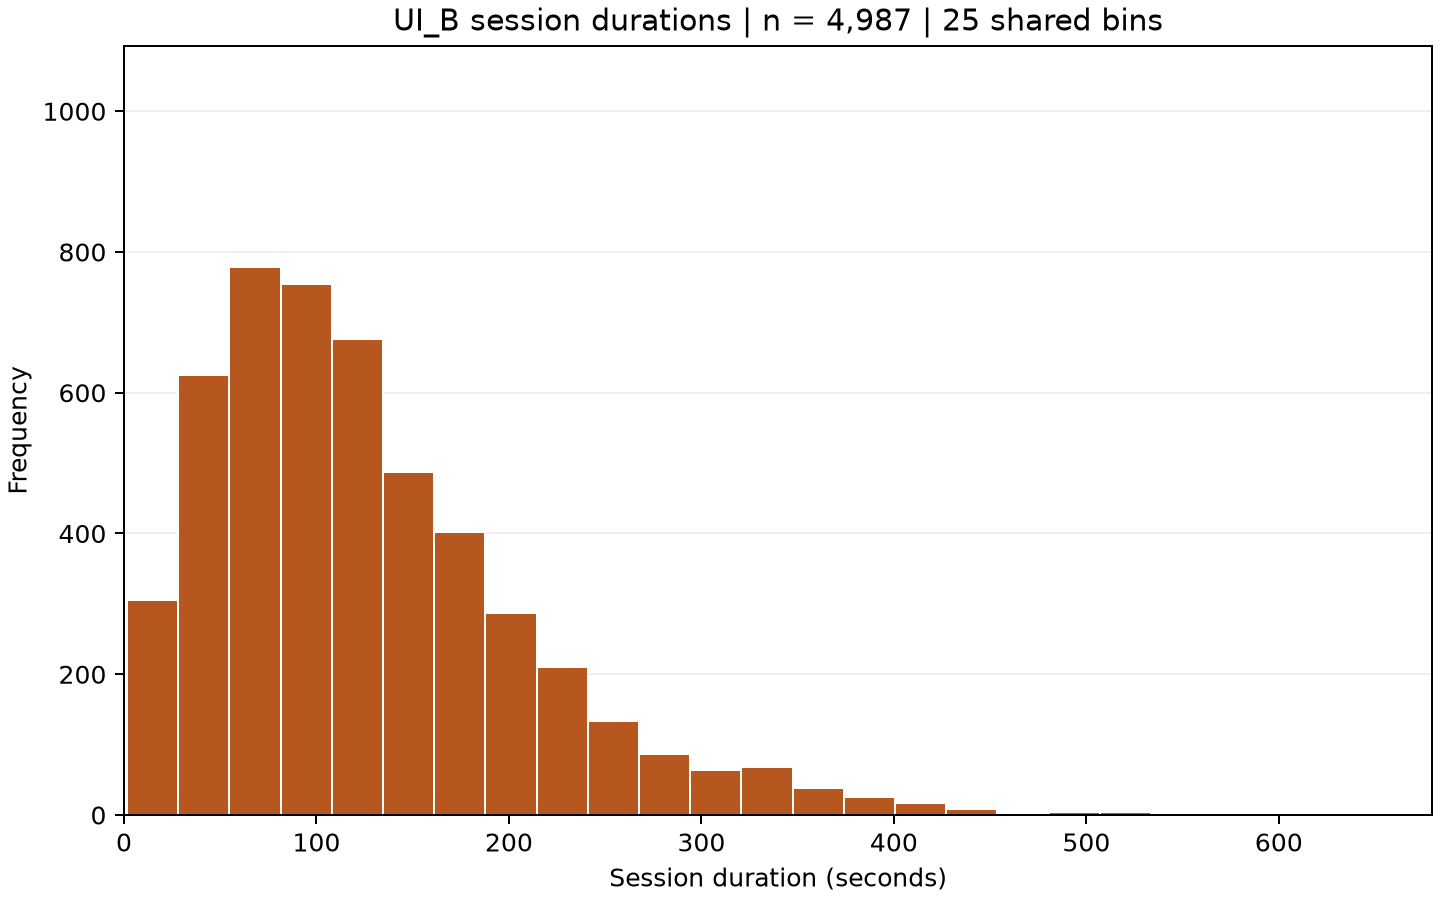

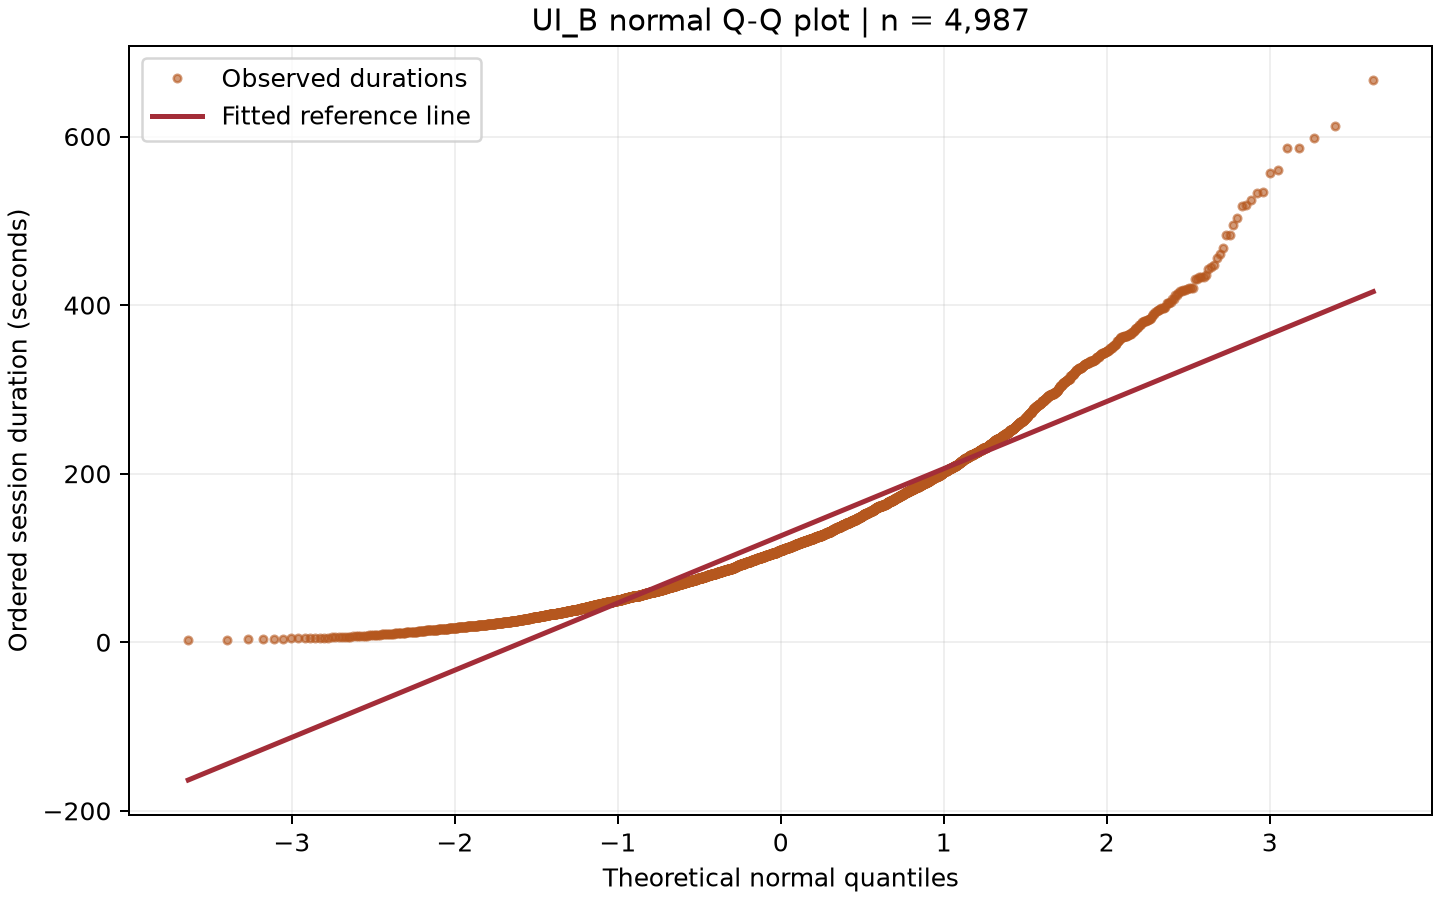

In [9]:
from scripts.analyze_ab_testing import create_normality_figures
from IPython.display import Image
figure_paths = create_normality_figures({'UI_A': ui_a, 'UI_B': ui_b}, ROOT / 'figures')
for figure_path in figure_paths:
    display(Image(filename=str(figure_path), width=800))

> Historical Step 3 checkpoint: the tests deferred here are performed in Step 4 below.

# Step 3: normality assessment

All four exported figures were visually inspected before writing this interpretation.
Titles, group assignments, sample sizes, axes, and fitted reference lines are readable.

## Visual evidence

Both 25-bin histograms are unimodal and clearly right-skewed rather than symmetric
bell shapes. UI_A peaks in the shared bin around 28-55 seconds; UI_B peaks around
55-81 seconds. Both show long, sparse right tails. UI_B extends farther to the
right (maximum 666.51 seconds versus 525.95 for UI_A). Shared bin boundaries and
identical histogram axes permit direct comparison of frequencies.

Both normal Q-Q plots show pronounced upward curvature. Lower-tail points lie
above the fitted line and remain positive where the line extrapolates below zero;
many central points fall below the line, and upper-tail points rise markedly above
it. These systematic departures are inconsistent with normally distributed
individual durations. Negative fitted-line values are reference extrapolations,
not negative observed durations. The measured sample skewness is positive and
about 1.37 in both groups, consistent with the inspected plots.

## Shapiro-Wilk evidence and warning

H0: the group's individual durations follow a normal distribution.
H1: they do not follow a normal distribution. At alpha=0.05, both reported
p-values are far below the threshold, providing evidence against normality.
A large p-value would mean failure to reject H0, not proof of normality.
Large samples make normality tests sensitive even to small departures; here,
the visual departures and skewness also show substantial asymmetry.

UI_A uses all 5,013 observations and generates this captured SciPy warning:

> scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5013.

The exact UI_A p-value should therefore be treated cautiously, not as precisely
calibrated. SciPy documents that W remains accurate above 5,000 observations,
whereas the p-value may not. UI_B uses all 4,987 observations and does not trigger
that warning. No observations were subsampled and no warning was silently
suppressed: the warning is printed in both entry points and stored in the CSV.
The qualitative conclusion combines the test output with the visible curvature
and positive skewness rather than relying solely on UI_A's p-value magnitude.

Source: [SciPy Shapiro-Wilk documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html).

## Implications for later mean comparison

The distribution of individual durations differs from the sampling distribution
of a mean across repeated samples. Under independent sampling and finite population
variance, the central limit theorem supports an approximately normal sampling
distribution of the mean for sufficiently large samples even when individual
durations are non-normal. With roughly 5,000 observations per group, approximate
t-test inference for the difference in means may be reasonable under those
assumptions; raw-data normality is not established or required to become true.
Large sample size does not repair dependence, bias, or an unsuitable sampling design.

Independence is an assumption supplied by the assignment's scenario. Unique
session IDs do not establish independent users or observations, and the CSV alone
does not verify the collection design. Welch's test is a candidate for the next
stage because it accommodates unequal variances; it does not make the raw data
normal. No variance test or two-sample test has been performed at this stage.

All extreme values remain included. No durations were transformed and the
original files are unchanged. Probability scenarios and final-report creation
remain deferred.


## Step 4: independent two-sample t-test

Target: population mean session duration, in seconds. Direction: **UI_B minus UI_A** throughout. H0: $\mu_B-\mu_A=0$; H1: $\mu_B-\mu_A\ne0$. Two-sided alpha = 0.05. Retain all observations without transformations.

Median-centered Levene tests equal population variances and is robust to departures from normality, especially skewness. A non-significant result does not prove equal variances. Follow the assignment rule: p < 0.05 selects Welch; otherwise select Student pooled and report Welch as sensitivity. This data-dependent preliminary selection can affect the overall error properties and is not universally optimal.

In [10]:
alpha = 0.05
variance_result = scipy_stats.levene(ui_b, ui_a, center='median')
use_pooled = bool(variance_result.pvalue >= alpha)
variance_notebook = pd.DataFrame([{
    'test_name': 'Levene (median-centered / Brown-Forsythe)',
    'statistic': variance_result.statistic, 'p_value': variance_result.pvalue,
    'alpha': alpha, 'selected_test': 'Student pooled' if use_pooled else 'Welch',
    'reject_equal_variances': bool(variance_result.pvalue < alpha)
}])
print(variance_notebook.to_string(index=False, formatters={'p_value': '{:.8e}'.format}))
display(statistics[['count', 'mean', 'std']])

                                test_name  statistic        p_value  alpha selected_test  reject_equal_variances
Levene (median-centered / Brown-Forsythe)    65.9193 5.25152025e-16 0.0500         Welch                    True


,count,mean,std
ui_version,,,
UI_A,5013,99.6631,71.5636
UI_B,4987,126.2585,83.6444


### Raw-data SciPy test and independent summary formulas

For Welch, $SE=\sqrt{s_B^2/n_B+s_A^2/n_A}$, and $df=(s_B^2/n_B+s_A^2/n_A)^2 / [(s_B^2/n_B)^2/(n_B-1)+(s_A^2/n_A)^2/(n_A-1)]$.

For Student, $s_p^2=[(n_B-1)s_B^2+(n_A-1)s_A^2]/(n_B+n_A-2)$, $SE=\sqrt{s_p^2(1/n_B+1/n_A)}$, and $df=n_B+n_A-2$.

For either: $t=(\bar{x}_B-\bar{x}_A)/SE$, two-sided $p=2\,t.sf(|t|,df)$, and 95% CI is difference $\pm t.ppf(0.975,df)\,SE$. All computations use full precision; display rounding does not affect calculations.

In [11]:
nB, nA = len(ui_b), len(ui_a)
mB, mA = float(ui_b.mean()), float(ui_a.mean())
sB, sA = float(ui_b.std(ddof=1)), float(ui_a.std(ddof=1))
delta = mB - mA
choices = [(use_pooled, 'selected')] + ([(False, 'sensitivity')] if use_pooled else [])
notebook_rows = []
for equal_var, role in choices:
    raw = scipy_stats.ttest_ind(ui_b, ui_a, equal_var=equal_var, alternative='two-sided')
    raw_ci = raw.confidence_interval(confidence_level=0.95)
    if equal_var:
        sp2 = ((nB-1)*sB*sB + (nA-1)*sA*sA)/(nB+nA-2)
        standard_error = np.sqrt(sp2*(1/nB + 1/nA))
        degrees = nB+nA-2
    else:
        vB, vA = sB*sB/nB, sA*sA/nA
        standard_error = np.sqrt(vB+vA)
        degrees = (vB+vA)**2/(vB*vB/(nB-1) + vA*vA/(nA-1))
    t_manual = delta/standard_error
    p_manual = 2*scipy_stats.t.sf(abs(t_manual), degrees)
    half_width = scipy_stats.t.ppf(0.975, degrees)*standard_error
    lo_manual, hi_manual = delta-half_width, delta+half_width
    np.testing.assert_allclose([t_manual, degrees, lo_manual, hi_manual],
        [raw.statistic, raw.df, raw_ci.low, raw_ci.high], rtol=1e-12, atol=0)
    assert p_manual > 0 and raw.pvalue > 0
    np.testing.assert_allclose(p_manual, raw.pvalue, rtol=1e-10, atol=0)
    notebook_rows.append({
        'test_name': 'Student pooled' if equal_var else 'Welch', 'role': role,
        'difference_direction': 'UI_B minus UI_A', 'alternative': 'two-sided',
        'alpha': alpha, 'equal_var': equal_var,
        'n_B': nB, 'mean_B': mB, 'sample_sd_B': sB,
        'n_A': nA, 'mean_A': mA, 'sample_sd_A': sA,
        'mean_difference_seconds': delta, 'standard_error_seconds': standard_error,
        't_statistic': raw.statistic, 'degrees_of_freedom': raw.df,
        'p_value': raw.pvalue, 'ci_95_low_seconds': raw_ci.low,
        'ci_95_high_seconds': raw_ci.high,
        'decision': 'Reject H0' if raw.pvalue < alpha else 'Fail to reject H0',
        'manual_t': t_manual, 'manual_df': degrees, 'manual_p_value': p_manual,
        'manual_ci_low': lo_manual, 'manual_ci_high': hi_manual, 'manual_verified': True
    })
tests_notebook = pd.DataFrame(notebook_rows)
print(tests_notebook.to_string(index=False, formatters={'p_value': '{:.8e}'.format, 'manual_p_value': '{:.8e}'.format}))
print('PASS: notebook manual formulas agree with raw-data SciPy; p-value atol=0.')

test_name     role difference_direction alternative  alpha  equal_var  n_B   mean_B  sample_sd_B  n_A  mean_A  sample_sd_A  mean_difference_seconds  standard_error_seconds  t_statistic  degrees_of_freedom        p_value  ci_95_low_seconds  ci_95_high_seconds  decision  manual_t  manual_df manual_p_value  manual_ci_low  manual_ci_high  manual_verified
    Welch selected      UI_B minus UI_A   two-sided 0.0500      False 4987 126.2585      83.6444 5013 99.6631      71.5636                  26.5954                  1.5571      17.0802           9748.8291 1.79827227e-64            23.5432             29.6476 Reject H0   17.0802  9748.8291 1.79827227e-64        23.5432         29.6476             True
PASS: notebook manual formulas agree with raw-data SciPy; p-value atol=0.


### Verify notebook against saved script results

No large absolute tolerance is permitted for tiny p-values. Compare all saved columns and use relative-only comparisons, with explicit positive-p checks.

In [12]:
for filename, calculated in [('variance_test.csv', variance_notebook), ('t_test_results.csv', tests_notebook)]:
    saved = pd.read_csv(ROOT / 'results' / filename, float_precision='round_trip')
    pd.testing.assert_frame_equal(calculated, saved, check_exact=False, rtol=1e-10, atol=0)
    for column in [name for name in calculated.columns if 'p_value' in name]:
        assert (calculated[column] > 0).all() and (saved[column] > 0).all()
        np.testing.assert_allclose(calculated[column], saved[column], rtol=1e-10, atol=0)
print('PASS: script, notebook, and manual t-test calculations agree.')

PASS: script, notebook, and manual t-test calculations agree.


> Historical Step 4 checkpoint: the probability and percentage calculations deferred here are completed in Step 5 below.

# Step 4: independent two-sample mean comparison

The target is population mean session duration in seconds. All differences are
UI_B minus UI_A. H0: mu_B - mu_A = 0; H1: mu_B - mu_A != 0.
The test is two-sided at alpha = 0.05. All original observations are retained,
without transformations or removal of extreme values.

## Variance assessment and selection

Median-centered Levene's test (Brown-Forsythe variant), called with UI_B first,
gives statistic 65.919294 and p = 5.25152025e-16. This is evidence against equal
population variances. Following the assignment's rule, select Welch's t-test
(`equal_var=False`). Had p been at least 0.05, the workflow would select Student's
pooled-variance test and additionally report Welch's as a sensitivity check.
A non-significant variance test would not prove equal variances.

Median centering makes the variance check more robust to departures from
normality, particularly skewness. It is not assumption-free. Selecting the mean
test through a preliminary variance test has limitations: the selection itself
is data-dependent, and nominal error rates of the resulting two-stage procedure
need not match those of either pre-specified test. This workflow follows the
assignment's rule rather than treating it as an universally optimal strategy.

Sources: [SciPy Levene documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.levene.html)
and [SciPy independent t-test documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html).

## Results (rounded for display only)

| Group | n | Mean (seconds) | Sample SD (ddof=1; seconds) |
|---|---:|---:|---:|
| UI_A | 5013 | 99.663074 | 71.563620 |
| UI_B | 4987 | 126.258486 | 83.644361 |

- Mean difference, UI_B minus UI_A: 26.595412 seconds.
- Standard error of the difference: 1.557093 seconds.
- Welch t-statistic: 17.080173.
- Welch-Satterthwaite degrees of freedom: 9748.829140.
- Two-sided p-value: 1.79827227e-64.
- 95% confidence interval for mu_B - mu_A: [23.543188, 29.647637] seconds.
- Decision at alpha = 0.05: reject H0.

UI_B has a higher estimated mean session duration by about 26.60 seconds. The
confidence interval is wholly positive and excludes zero. Under the stated
sampling assumptions, the data provide strong evidence of a difference in
population mean durations. The p-value measures tail extremeness under H0 and
the test model; it is not the probability that H0 is true.

Statistical significance does not establish business importance. Assessing
practical value requires a meaningful decision threshold, implementation costs,
and relevant outcomes. Longer sessions may reflect engagement or difficulty;
they do not by themselves prove better usability or user satisfaction. No
percentage increase or probability scenarios are calculated here.

## Assumptions and verification

Step 3 found non-normal, right-skewed individual durations. With roughly 5,000
observations per group, independent sampling and finite population variances
support approximate normal sampling distributions for the means and approximate
mean-difference inference. This does not make individual durations normal.
Welch accommodates unequal variances, not non-normality itself. Independence
remains an assumption supplied by the assignment scenario, not established by
unique IDs. Large samples do not correct dependence or biased sampling.

The script and notebook calculate summary-statistic SE, t, degrees of freedom,
two-sided p = 2*t.sf(abs(t), df), and confidence limits from full-precision data.
These are compared against SciPy's raw-data t-test and its confidence_interval
method. P-value checks use relative tolerance 1e-10 and absolute tolerance zero,
with explicit positivity checks, so an erroneous zero cannot pass. Other manual
comparisons use relative tolerance 1e-12 and absolute tolerance zero. The notebook
also checks agreement with the script's saved results. No final report has been
created; this is the Step 4 interpretation only.


## Step 5: normal-model probabilities and separate empirical comparisons

Use XA ~ Normal(mA, sA squared) and XB ~ Normal(mB, sB squared), with **individual-duration sample SDs (ddof=1), not standard errors**. These untruncated normal-model approximations are required by the assignment despite right-skewed, non-normal observations. Large samples support mean inference but do not make individual durations normal. Question (a) holds the observed UI_B mean fixed; it is not P(XA > XB).

In [13]:
mA, sA = ui_a.mean(), ui_a.std(ddof=1)
mB, sB = ui_b.mean(), ui_b.std(ddof=1)
z_a = (mB-mA)/sA
z_b = (80-mA)/sA
z_c = (150-mB)/sB
z_d_lower, z_d_upper = (80-mA)/sA, (120-mA)/sA
model_probabilities = np.array([
    scipy_stats.norm.sf(z_a),
    scipy_stats.norm.cdf(z_b),
    scipy_stats.norm.sf(z_c),
    scipy_stats.norm.cdf(z_d_upper)-scipy_stats.norm.cdf(z_d_lower)
])
direct_probabilities = np.array([
    scipy_stats.norm.sf(mB, loc=mA, scale=sA),
    scipy_stats.norm.cdf(80, loc=mA, scale=sA),
    scipy_stats.norm.sf(150, loc=mB, scale=sB),
    scipy_stats.norm.cdf(120, loc=mA, scale=sA)-scipy_stats.norm.cdf(80, loc=mA, scale=sA)
])
np.testing.assert_allclose(model_probabilities, direct_probabilities, rtol=1e-13, atol=0)
assert np.isfinite(model_probabilities).all()
assert ((model_probabilities >= 0) & (model_probabilities <= 1)).all()
print('PASS: all four z-score probabilities match direct loc/scale probabilities and lie in [0,1].')

PASS: all four z-score probabilities match direct loc/scale probabilities and lie in [0,1].


### Observed event counts: supplementary, not model answers

Use strict inequalities and the matching group denominator. The first event uses the full-precision UI_B mean. Verify vectorized counts independently by iterating over original values.

In [14]:
counts = np.array([int((ui_a > mB).sum()), int((ui_a < 80).sum()),
                   int((ui_b > 150).sum()), int(((ui_a > 80) & (ui_a < 120)).sum())])
independent_counts = np.array([sum(x > mB for x in ui_a), sum(x < 80 for x in ui_a),
                              sum(x > 150 for x in ui_b), sum(80 < x < 120 for x in ui_a)])
np.testing.assert_array_equal(counts, independent_counts)
denominators = np.array([len(ui_a), len(ui_a), len(ui_b), len(ui_a)])
source_denominators = np.array([int(data['ui_version'].eq(g).sum()) for g in ['UI_A','UI_A','UI_B','UI_A']])
np.testing.assert_array_equal(denominators, source_denominators)
assert ((counts >= 0) & (counts <= denominators)).all()
observed = counts/denominators
assert ((observed >= 0) & (observed <= 1)).all()
probability_notebook = pd.DataFrame({
    'question': ['a','b','c','d'],
    'z_lower': [z_a, -np.inf, z_c, z_d_lower],
    'z_upper': [np.inf, z_b, np.inf, z_d_upper],
    'normal_probability': model_probabilities, 'normal_percentage': 100*model_probabilities,
    'empirical_count': counts, 'denominator': denominators,
    'empirical_proportion': observed, 'empirical_percentage': 100*observed,
    'empirical_minus_normal_percentage_points': 100*(observed-model_probabilities)
})
display(probability_notebook)
saved_probabilities = pd.read_csv(ROOT / 'results' / 'probability_scenarios.csv', float_precision='round_trip')
pd.testing.assert_frame_equal(probability_notebook, saved_probabilities[probability_notebook.columns], check_exact=False, rtol=1e-12, atol=0, check_dtype=False)
np.testing.assert_array_equal(counts, saved_probabilities['empirical_count'])
np.testing.assert_array_equal(denominators, saved_probabilities['denominator'])
assert saved_probabilities.loc[0, 'lower_bound_seconds'] == mB
print('PASS: strict empirical counts, matching denominators, full-precision threshold, and script/notebook probabilities verified.')

,question,z_lower,z_upper,normal_probability,normal_percentage,empirical_count,denominator,empirical_proportion,empirical_percentage,empirical_minus_normal_percentage_points
0,a,0.3716,inf,0.3551,35.5083,1405,5013,0.2803,28.0271,-7.4812
1,b,-inf,-0.2748,0.3917,39.1749,2448,5013,0.4883,48.8330,9.6581
2,c,0.2838,inf,0.3883,38.8267,1542,4987,0.3092,30.9204,-7.9063
3,d,-0.2748,0.2842,0.2201,22.0115,1057,5013,0.2109,21.0852,-0.9263


PASS: strict empirical counts, matching denominators, full-precision threshold, and script/notebook probabilities verified.


### Business impact

Absolute difference = mB - mA. Percentage increase = 100 * (mB - mA) / mA. This is a relative percentage increase, not a percentage-point change. Reuse the verified mean comparison and its confidence interval.

In [15]:
absolute_difference = mB-mA
percentage_increase = 100*absolute_difference/mA
selected_test = tests_notebook.loc[tests_notebook['role'].eq('selected')].iloc[0]
business_notebook = pd.DataFrame([{
    'mean_A_seconds': mA, 'mean_B_seconds': mB,
    'absolute_difference_seconds': absolute_difference, 'percentage_increase': percentage_increase,
    'difference_direction': 'UI_B minus UI_A', 'test_name': selected_test['test_name'],
    'p_value': selected_test['p_value'],
    'ci_95_low_seconds': selected_test['ci_95_low_seconds'],
    'ci_95_high_seconds': selected_test['ci_95_high_seconds'],
    'statistically_significant': bool(selected_test['p_value'] < 0.05)
}])
saved_business = pd.read_csv(ROOT / 'results' / 'business_impact.csv', float_precision='round_trip')
pd.testing.assert_frame_equal(business_notebook, saved_business, check_exact=False, rtol=1e-12, atol=0)
assert (business_notebook['p_value'] > 0).all()
print(f'Absolute difference = {mB:.10f} - {mA:.10f} = {absolute_difference:.10f} seconds')
print(f'Percentage increase = 100 * ({mB:.10f} - {mA:.10f}) / {mA:.10f} = {percentage_increase:.8f}%')
print(business_notebook.to_string(index=False, formatters={'p_value': '{:.8e}'.format}))
print('PASS: script and notebook business impact and verified test results agree.')

Absolute difference = 126.2584860638 - 99.6630740076 = 26.5954120562 seconds
Percentage increase = 100 * (126.2584860638 - 99.6630740076) / 99.6630740076 = 26.68532184%
 mean_A_seconds  mean_B_seconds  absolute_difference_seconds  percentage_increase difference_direction test_name        p_value  ci_95_low_seconds  ci_95_high_seconds  statistically_significant
        99.6631        126.2585                      26.5954              26.6853      UI_B minus UI_A     Welch 1.79827227e-64            23.5432             29.6476                       True
PASS: script and notebook business impact and verified test results agree.


# Step 5: probability scenarios and business impact

## Required normal-model approximations

XA ~ Normal(mA, sA^2) and XB ~ Normal(mB, sB^2), using CSV sample means
and individual-duration sample SDs (ddof=1), NOT standard errors.
Displayed substitutions are rounded; computations retain full precision.

Both groups are right-skewed and non-normal. These are the assignment-required
normal-model approximations, not validated individual-duration distributions.
Large independent samples support inference for means but do not make individual
durations normal. The requested normal models remain untruncated, including their
theoretical support below zero; no data or model transformations are applied.

### (a) A UI_A session exceeds the UI_B sample mean

Mean = 99.6630740076 seconds; sample SD = 71.5636198220 seconds.
z_lower = (126.2584860638 - 99.6630740076) / 71.5636198220 = 0.3716331304.
Formula: `norm.sf((lower - mean) / sample_sd)`.
Substitution: norm.sf(0.3716331304) = 0.3550830093 = 35.508301%.
Under the normal approximation, about 35.51% of individual UI_A sessions satisfy this event.

The threshold is UI_B's full-precision sample mean, held fixed. This is NOT P(XA > XB).

### (b) A UI_A session lasts less than 80 seconds

Mean = 99.6630740076 seconds; sample SD = 71.5636198220 seconds.
z_upper = (80.0000000000 - 99.6630740076) / 71.5636198220 = -0.2747635468.
Formula: `norm.cdf((upper - mean) / sample_sd)`.
Substitution: norm.cdf(-0.2747635468) = 0.3917489530 = 39.174895%.
Under the normal approximation, about 39.17% of individual UI_A sessions satisfy this event.

### (c) A UI_B session lasts more than 150 seconds

Mean = 126.2584860638 seconds; sample SD = 83.6443611028 seconds.
z_lower = (150.0000000000 - 126.2584860638) / 83.6443611028 = 0.2838387863.
Formula: `norm.sf((lower - mean) / sample_sd)`.
Substitution: norm.sf(0.2838387863) = 0.3882669646 = 38.826696%.
Under the normal approximation, about 38.83% of individual UI_B sessions satisfy this event.

### (d) A UI_A session lasts strictly between 80 and 120 seconds

Mean = 99.6630740076 seconds; sample SD = 71.5636198220 seconds.
z_lower = (80.0000000000 - 99.6630740076) / 71.5636198220 = -0.2747635468.
z_upper = (120.0000000000 - 99.6630740076) / 71.5636198220 = 0.2841796718.
Formula: `norm.cdf(z_upper) - norm.cdf(z_lower)`.
Substitution: norm.cdf(0.2841796718) - norm.cdf(-0.2747635468) = 0.2201147005 = 22.011470%.
Under the normal approximation, about 22.01% of individual UI_A sessions satisfy this event.

## Supplementary empirical comparison

Observed proportions use the matching group denominator and strict inequalities.
They describe this sample directly and are not replacements for the required model answers.

| Question | Count / denominator | Observed proportion | Observed % | Normal-model % | Observed minus model (percentage points) |
|---|---:|---:|---:|---:|---:|
| a | 1405 / 5013 | 0.2802712946 | 28.027129 | 35.508301 | -7.481171 |
| b | 2448 / 5013 | 0.4883303411 | 48.833034 | 39.174895 | +9.658139 |
| c | 1542 / 4987 | 0.3092039302 | 30.920393 | 38.826696 | -7.906303 |
| d | 1057 / 5013 | 0.2108517854 | 21.085179 | 22.011470 | -0.926292 |

Differences reflect the normal approximation versus the observed, skewed distribution;
empirical rates are sample estimates, not exact population probabilities.

## Business impact

Absolute difference = mB - mA = 126.2584860638 - 99.6630740076 = 26.5954120562 seconds.
Percentage increase = 100 * (mB - mA) / mA = 100 * (126.2584860638 - 99.6630740076) / 99.6630740076 = 26.68532184%.
This is a relative percentage increase in mean duration, not percentage points.
The verified Step 4 Welch test gives two-sided p = 1.79827227e-64 and 95% CI [23.54318756, 29.64763655] seconds for UI_B minus UI_A.
The mean difference is statistically significant at alpha=0.05; the interval excludes zero.
Statistical significance does not establish business importance. If longer engagement is
the business objective, UI_B is a candidate for adoption, conditional on practical value,
implementation costs, and checks of relevant outcomes. Longer sessions alone do not prove
improved usability, satisfaction, revenue, or conversion; they could also reflect friction.
Independence remains the assignment-supplied assumption, not a consequence of unique IDs.

## Verification and scope

Z-score probabilities are verified against norm.cdf/norm.sf with loc and scale directly.
All probabilities are within [0,1]. Event counts are checked by direct iteration as well
as vectorized strict comparisons. The full notebook independently recomputes and checks
these results against the script CSVs. Earlier verified results and originals are preserved.
No final report is created in Step 5.
